In [ ]:
import pandas as pd
import numpy as np

sessions = pd.read_csv("../data/website_sessions.csv")
orders = pd.read_csv("../data/orders_mav.csv")

print(f"Shape website_sessions : {sessions.shape}")
print(f"Shape orders_mav       : {orders.shape}")
print("\nColonnes website_sessions :", sessions.columns.tolist())
print("Colonnes orders_mav       :", orders.columns.tolist())

df = sessions.merge(
    orders[["website_session_id", "order_id"]],
    on="website_session_id",
    how="left"
)

df["converted"] = df["order_id"].notna().astype(int)
df = df.drop(columns=["order_id"])

print("\n--- Valeurs manquantes par colonne ---")
print(df.isnull().sum())

conv_rate = df["converted"].mean() * 100
print(f"\nTaux de conversion global : {conv_rate:.2f}% ({df['converted'].sum()} achats sur {len(df)} sessions)")
df.head()

Shape website_sessions : (472871, 9)
Shape orders_mav       : (32313, 8)

Colonnes website_sessions : ['website_session_id', 'created_at', 'user_id', 'is_repeat_session', 'utm_source', 'utm_campaign', 'utm_content', 'device_type', 'http_referer']
Colonnes orders_mav       : ['order_id', 'created_at', 'website_session_id', 'user_id', 'primary_product_id', 'items_purchased', 'price_usd', 'cogs_usd']

--- Valeurs manquantes par colonne ---
website_session_id        0
created_at                0
user_id                   0
is_repeat_session         0
utm_source            83328
utm_campaign          83328
utm_content           83328
device_type               0
http_referer          39917
converted                 0
dtype: int64

Taux de conversion global : 6.83% (32313 achats sur 472871 sessions)


,website_session_id,created_at,user_id,is_repeat_session,utm_source,utm_campaign,utm_content,device_type,http_referer,converted
0,1,3/19/2012 8:04,1,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,0
1,2,3/19/2012 8:16,2,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,0
2,3,3/19/2012 8:26,3,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,0
3,4,3/19/2012 8:37,4,0,gsearch,nonbrand,g_ad_1,desktop,https://www.gsearch.com,0
4,5,3/19/2012 9:00,5,0,gsearch,nonbrand,g_ad_1,mobile,https://www.gsearch.com,0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df["created_at"] = pd.to_datetime(df["created_at"])
df = df.sort_values("created_at").reset_index(drop=True)

utm_cols = ["utm_source", "utm_campaign", "utm_content"]
for col in utm_cols:
    df[col] = df[col].fillna("organic_or_direct")

df["http_referer"] = df["http_referer"].fillna("direct_type_in")

df["hour"] = df["created_at"].dt.hour
df["day_of_week"] = df["created_at"].dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

print("--- Taux de conversion par appareil ---")
print(df.groupby("device_type")["converted"].agg(["count", "mean"]).assign(conv_pct=lambda x: x["mean"]*100))

print("\n--- Taux de conversion par source marketing ---")
print(df.groupby("utm_source")["converted"].agg(["count", "mean"]).assign(conv_pct=lambda x: x["mean"]*100))

feature_cols = [
    "is_repeat_session", "utm_source", "utm_campaign",
    "utm_content", "device_type", "http_referer",
    "hour", "day_of_week", "is_weekend"
]
prepared_df = df[["website_session_id", "created_at"] + feature_cols + ["converted"]]
prepared_df.to_csv("../data/prepared_modelling_dataset.csv", index=False)
print("\nDataset préparé sauvegardé dans ../data/prepared_modelling_dataset.csv")

--- Taux de conversion par appareil ---
              count      mean  conv_pct
device_type                            
desktop      327027  0.085024  8.502356
mobile       145844  0.030910  3.090974

--- Taux de conversion par source marketing ---
                    count      mean  conv_pct
utm_source                                   
bsearch             62823  0.071932  7.193225
gsearch            316035  0.067502  6.750202
organic_or_direct   83328  0.073421  7.342070
socialbook          10685  0.032101  3.210108

Dataset préparé sauvegardé dans ../data/prepared_modelling_dataset.csv


In [ ]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report, roc_auc_score
)

split_idx = int(len(prepared_df) * 0.80)
train_df = prepared_df.iloc[:split_idx].copy()
test_df = prepared_df.iloc[split_idx:].copy()

print(f"Période Train : {train_df['created_at'].min()} -> {train_df['created_at'].max()} ({len(train_df)} sessions, conv: {train_df['converted'].mean()*100:.2f}%)")
print(f"Période Test  : {test_df['created_at'].min()} -> {test_df['created_at'].max()} ({len(test_df)} sessions, conv: {test_df['converted'].mean()*100:.2f}%)")

X_train, y_train = train_df[feature_cols], train_df["converted"]
X_test, y_test = test_df[feature_cols], test_df["converted"]

categorical_features = ["utm_source", "utm_campaign", "utm_content", "device_type", "http_referer"]
numeric_features = ["is_repeat_session", "hour", "day_of_week", "is_weekend"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numeric_features)
    ]
)

pipe_standard = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

pipe_balanced = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

pipe_standard.fit(X_train, y_train)
pipe_balanced.fit(X_train, y_train)

results = []
for name, model in [("Logistic Regression (Standard)", pipe_standard), ("Logistic Regression (Balanced)", pipe_balanced)]:
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
print("\n--- Résultats comparatifs sur le jeu de Test ---")
print(results_df.to_string(index=False))

joblib.dump(pipe_balanced, "../models/logistic_regression_conversion.joblib")
print("\nModèle sauvegardé dans ../models/logistic_regression_conversion.joblib")

Période Train : 2012-03-19 08:04:00 -> 2014-11-28 23:32:00 (378296 sessions, conv: 6.48%)
Période Test  : 2014-11-28 23:32:00 -> 2015-03-19 07:59:00 (94575 sessions, conv: 8.23%)

--- Résultats comparatifs sur le jeu de Test ---
                         Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
Logistic Regression (Standard)  0.917706    0.00000 0.000000  0.000000 0.606089
Logistic Regression (Balanced)  0.377531    0.10386 0.860465  0.185348 0.606229

Modèle sauvegardé dans ../models/logistic_regression_conversion.joblib


C:\Users\DJAGBA\AppData\Local\Temp\ipykernel_1428\2244776785.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conv_source.values, y=conv_source.index, ax=axes[0], palette="viridis")
C:\Users\DJAGBA\AppData\Local\Temp\ipykernel_1428\2244776785.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Coefficient", y="Feature", data=top_features, palette=colors, ax=axes[2])


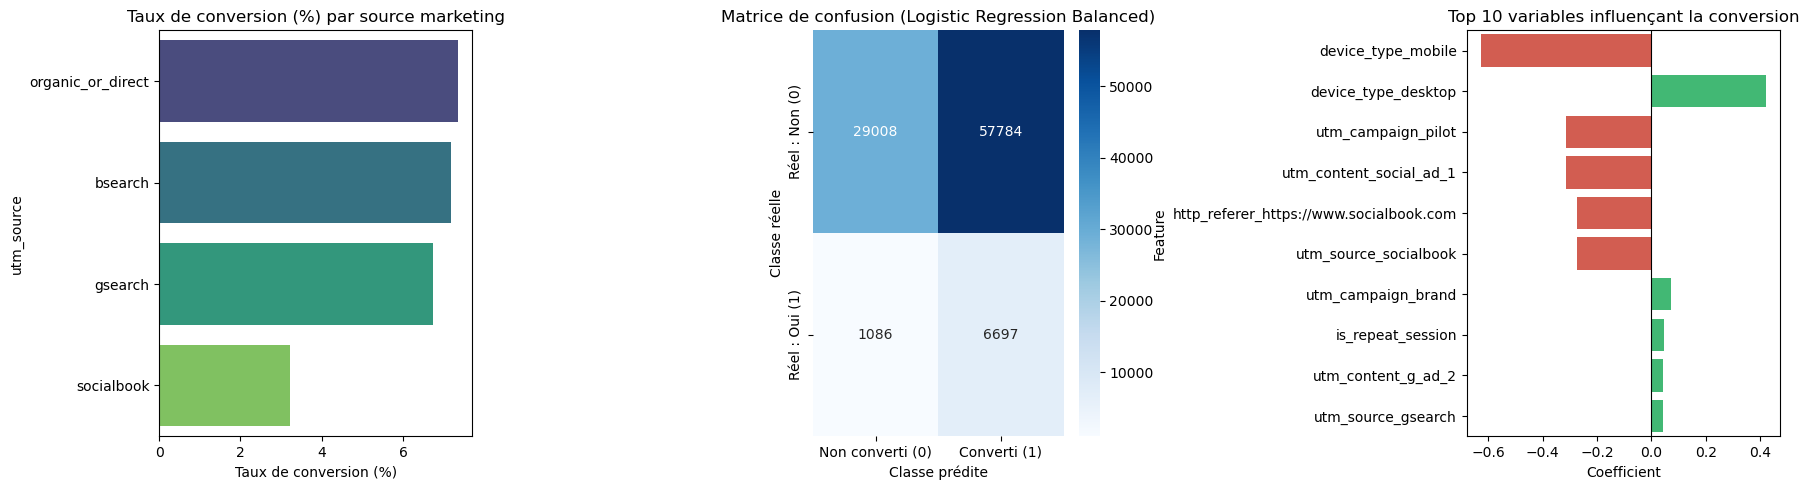


--- Top 10 des facteurs prédictifs (Log-Odds) ---
                                Feature  Coefficient
                     device_type_mobile    -0.626476
                    device_type_desktop     0.419742
                     utm_campaign_pilot    -0.313273
                utm_content_social_ad_1    -0.313273
http_referer_https://www.socialbook.com    -0.272459
                  utm_source_socialbook    -0.272459
                     utm_campaign_brand     0.071263
                      is_repeat_session     0.045187
                     utm_content_g_ad_2     0.044100
                     utm_source_gsearch     0.043253


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

conv_source = df.groupby("utm_source")["converted"].mean().sort_values(ascending=False) * 100
sns.barplot(x=conv_source.values, y=conv_source.index, ax=axes[0], palette="viridis")
axes[0].set_title("Taux de conversion (%) par source marketing")
axes[0].set_xlabel("Taux de conversion (%)")

cm = confusion_matrix(y_test, y_pred_bal)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1],
            xticklabels=["Non converti (0)", "Converti (1)"],
            yticklabels=["Réel : Non (0)", "Réel : Oui (1)"])
axes[1].set_title("Matrice de confusion (Logistic Regression Balanced)")
axes[1].set_ylabel("Classe réelle")
axes[1].set_xlabel("Classe prédite")

ohe_names = pipe_balanced.named_steps["preprocessor"].named_transformers_["cat"].get_feature_names_out(categorical_features)
all_feature_names = list(ohe_names) + numeric_features
coefs = pipe_balanced.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({"Feature": all_feature_names, "Coefficient": coefs})
coef_df["Abs_Coef"] = coef_df["Coefficient"].abs()
top_features = coef_df.sort_values("Abs_Coef", ascending=False).head(10)

colors = ["#2ecc71" if c > 0 else "#e74c3c" for c in top_features["Coefficient"]]
sns.barplot(x="Coefficient", y="Feature", data=top_features, palette=colors, ax=axes[2])
axes[2].set_title("Top 10 variables influençant la conversion")
axes[2].axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.savefig("../models/evaluation_plots.png", dpi=150)
plt.show()

print("\n--- Top 10 des facteurs prédictifs (Log-Odds) ---")
print(top_features[["Feature", "Coefficient"]].to_string(index=False))